# Fit a microscope from MAGICAL images

1. Make images with a simulated microscope.
2. Measure scale, rotation, blur and the image shift caused by a known beam tilt.
3. Fit a second microscope, starting from guesses.
4. Compare fits **with and without the tilt measurements** against the true microscope.

We use **40,000× and 60,000×**, with one reference and ±2.5% wobbles of IL1–PL1 at each magnification: **18 images**. We add **eight tilt images**, keeping the same two magnifications.

Then we explore the fit from 20 starting guesses, scan detector position, and repeat after adding ±5% and ±10% wobbles at 40,000×.

In [1]:
from pathlib import Path
import os
import sys
import numpy as np

os.environ.setdefault("XLA_PYTHON_CLIENT_PREALLOCATE", "false")
import jax
jax.config.update("jax_enable_x64", True)

project_folder = next(
    folder for folder in [Path.cwd(), *Path.cwd().parents]
    if (folder / "src/temgym_core").is_dir()
)
example_folder = project_folder / "examples/microscope_models"
sys.path.insert(0, str(project_folder / "src"))
sys.path.insert(0, str(example_folder))

from projector_notebook_helpers import (
    simulate_experiment, measure_images, fit_microscope,
    load_position_priors, load_simulated_truth,
    show_images, show_measurements, show_position_priors,
    show_image_fit,
)

from projector_tilt_pipeline import (
    simulate_tilt_images, measure_tilt_images,
    show_tilt_measurements, compare_tilt_fits,
)

from projector_landscape import (
    simulate_extra_wobbles, measure_extra_wobble_images,
    combine_image_measurements, combine_tilt_measurements,
    make_starting_models, explore_fit_landscape, compare_fit_landscapes,
    compare_tilt_amplitudes,
)

%matplotlib inline
from projector_beam_shift_pipeline import (
    simulate_beam_shift_images, measure_beam_shift_images,
    combine_beam_shift_measurements, show_beam_shift_measurements,
    compare_beam_shift_fits,
)


## The model

We use five finite solenoid lenses. Their positions, lengths and strengths are unknown. We also fit the beam's convergence, angular spread and the sample's rotation: **19 parameters in total**.

In our usual ray coordinates,

$$
\begin{pmatrix}x_d\\y_d\\\theta_{x,d}\\\theta_{y,d}\\1\end{pmatrix}
=
\begin{pmatrix}
A_{xx}&A_{xy}&B_{xx}&B_{xy}&t_x\\
A_{yx}&A_{yy}&B_{yx}&B_{yy}&t_y\\
C_{xx}&C_{xy}&D_{xx}&D_{xy}&u_x\\
C_{yx}&C_{yy}&D_{yx}&D_{yy}&u_y\\
0&0&0&0&1
\end{pmatrix}
\begin{pmatrix}x_s\\y_s\\\theta_{x,s}\\\theta_{y,s}\\1\end{pmatrix}.
$$

$A$ describes magnification and rotation. $B$ describes how the starting angle changes the image position. At perfect focus, $B=0$. The image does not directly measure the outgoing angles described by $C$ and $D$.

We assume aligned lenses. The beam curvature and angular spread are unknown and fitted; zero curvature below is only a starting guess. Image shifts are measured separately, then differences within tilt pairs constrain the microscope.

## 1. Make the images

**Supply:** two magnifications, the illumination radius, wobble size, voltage and detector settings.

**Get back:** `experiment`, containing the images, lens commands and known specimen template. The true microscope parameters are saved separately for the final comparison.

The sample is our synthetic MAGICAL target, with 13 nm Si and 10 nm SiGe layers. This example uses its known intensity pattern, smoothed by 2 nm Gaussian components. It includes counting noise and read noise, but no coherent phase contrast. We keep the illumination profile fixed and use the same sample region throughout.

The illumination radius is **100 nm**, reduced from 160 nm. At 60,000×, its 200 nm diameter spans about 109 pixels on our 128-pixel detector, so the circular edge stays in view. The exposure rule is unchanged; the smaller spot concentrates the simulated dose into a smaller area.

In [2]:
experiment = simulate_experiment(
    magnifications=[40_000, 60_000],
    illumination_radius_m=100e-9,     # 100 nm radius: 200 nm illuminated diameter
    wobble_fraction=0.025,              # ±2.5% around each reference setting
    voltage_v=200_000,
    detector_pixel_size_m=110e-6,       # 110 micrometres per pixel
    detector_shape=(128, 128),
    output_directory=project_folder / "examples/generated/simple_magical_fit",
    random_seed=7391,
)

print("Number of images:", len(experiment.images))
print("Lens-command columns: IL1, IL2, IL3, PL1")

Number of images: 18
Lens-command columns: IL1, IL2, IL3, PL1


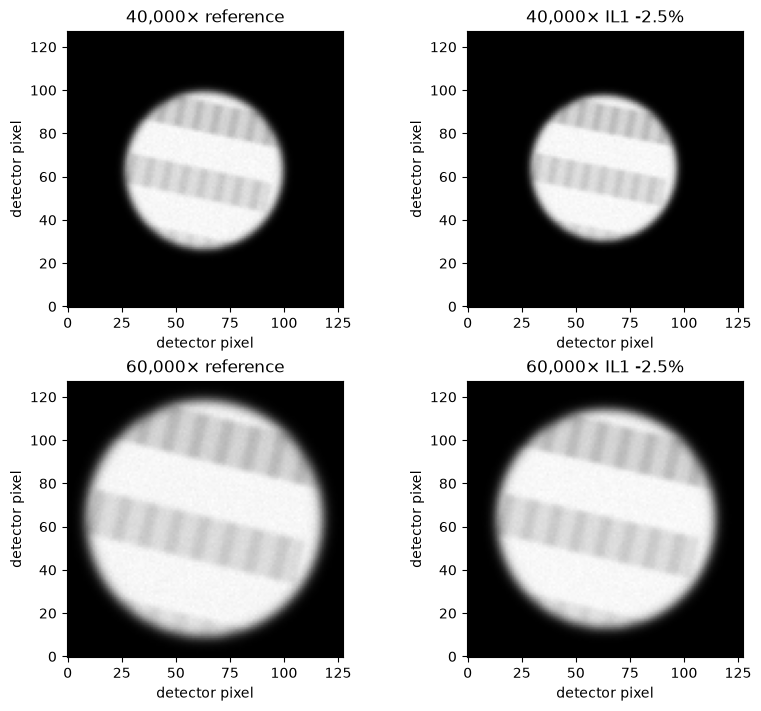

In [3]:
# Show a reference and one wobble image at each magnification.
show_images(
    images=experiment.images,
    image_labels=experiment.image_labels,
    indices=[0, 1, 9, 10],
)

## 2. Measure the images

**Supply:** the images, known sample pattern and detector settings. The magnification labels give the image search a starting point.

**Get back:** `measurements`, with one scale, rotation, blur width and uncertainty per image. Image position, brightness and background are also fitted so they do not have to be known.

This step knows nothing about the lens positions or strengths.

In [4]:
measurements = measure_images(
    images=experiment.images,
    nominal_magnifications=experiment.nominal_magnifications,
    specimen_template=experiment.specimen_template,
    specimen_and_detector=experiment.specimen_and_detector,
)

# These are the measured quantities that the microscope must explain.
show_measurements(
    measurements=measurements,
    image_labels=experiment.image_labels,
    indices=[0, 1, 9, 10],
)

Image,Measured scale,Rotation (degrees),Blur width (pixels)
"40,000× reference","39,999.4",-12.029,0.723
"40,000× IL1 -2.5%","36,996.5",-11.277,0.675
"60,000× reference","59,999.3",-13.794,1.089
"60,000× IL1 -2.5%","55,465.1",-13.025,1.015


## 3. Add known input tilts

At the IL1 −2.5% setting at each magnification, take images with **−1 and +1 mrad** tilts along $x$, then along $y$. Each pair keeps the projector fixed. For the same specimen feature,

$$
\Delta\mathbf{r}_d = B\,\Delta\boldsymbol{\theta}_s,
\qquad
\Delta\boldsymbol{\theta}_s=\boldsymbol{\theta}_{+}-\boldsymbol{\theta}_{-}.
$$

Detector pixel size converts image displacement to metres. Two tilt directions probe both columns of $B$. We use wobbled settings because $B=0$ at perfect focus.

Here the tilt is exactly calibrated at the specimen, with known axes and a fixed illumination footprint. Each pair shares an unknown image offset; independent frame drift has a known 0.003-pixel standard deviation. Subtraction removes the shared offset, and the measurement uncertainty includes drift. Real tilt-calibration errors, contrast changes and larger drift would weaken the result.

In [5]:
tilt_experiment = simulate_tilt_images(
    experiment=experiment,
    lens_setting_indices=[1, 10],     # IL1 −2.5% at 40,000× and 60,000×
    tilt_mrad=1.0,                    # each axis: −1 mrad, then +1 mrad
    drift_std_pixels=0.003,           # independent motion in each exposure
    random_seed=913,
)

print("Additional tilt images:", len(tilt_experiment.images))

Additional tilt images: 8


**Supply:** tilt images, the known specimen/detector, and the earlier image registration as a starting point.

**Get back:** `tilt_measurements`, with four measured displacement vectors, their uncertainties, the lens commands and calibrated angle changes. Displacements come from the pixels; image analysis receives no true lens parameters.

In [6]:
tilt_measurements = measure_tilt_images(
    tilt_experiment=tilt_experiment,
    specimen_template=experiment.specimen_template,
    specimen_and_detector=experiment.specimen_and_detector,
    reference_measurements=measurements,
)

show_tilt_measurements(tilt_measurements)

Lens setting / tilt direction,Measured dx (pixels),Measured dy (pixels)
"40,000× IL1 -2.5%, x tilt",-0.1740 ± 0.0046,+0.0610 ± 0.0046
"40,000× IL1 -2.5%, y tilt",-0.0678 ± 0.0046,-0.1778 ± 0.0046
"60,000× IL1 -2.5%, x tilt",-0.2625 ± 0.0046,+0.0901 ± 0.0046
"60,000× IL1 -2.5%, y tilt",-0.0941 ± 0.0046,-0.2618 ± 0.0046


## 4. Supply a starting guess and position bounds

All positions below are measured from the specimen. These are guesses, not the generating values.

The strength model uses an integrated solenoid strength `q`. For IL1–PL1, its magnitude is `gain × lens command`; each lens keeps its chosen polarity. The objective command stays fixed, but its strength is fitted.

In [7]:
starting_guess = {
    "lens_positions_mm": {
        "Objective": 2.75, "IL1": 196, "IL2": 281, "IL3": 336, "PL1": 399.6,
    },
    "lens_lengths_mm": {
        "Objective": 0.5, "IL1": 6, "IL2": 4, "IL3": 6, "PL1": 1.2,
    },
    "detector_position_mm": 740.2,
    "objective_strength": -0.40,
    "excitation_gains": {"IL1": 0.50, "IL2": 0.60, "IL3": 0.50, "PL1": 0.70},
    "beam_curvature_per_m": 0.0,       # start with no convergence or divergence
    "angular_spread_mrad": 1.2,
    "sample_rotation_deg": 0.0,
}

The position priors give a preferred position, an uncertainty and a hard allowed range. They are rough engineering estimates based on our current layout. The fit can move the lenses within these ranges.

The [editable prior file](projector_position_priors.json) also bounds lens lengths. These priors and a preference for the starting values help choose between microscopes that make similar images.

In [8]:
position_priors = load_position_priors(
    path=example_folder / "projector_position_priors.json",
)

show_position_priors(position_priors)

Element,Preferred position (mm),Uncertainty (mm),Allowed range (mm)
Objective,3.0,1.0,1.0 to 6.0
IL1,210.0,20.0,170.0 to 250.0
IL2,290.0,15.0,265.0 to 315.0
IL3,355.0,15.0,325.0 to 385.0
PL1,425.0,20.0,395.0 to 475.0
Detector,740.0,50.0,640.0 to 840.0


## 5. Fit with and without the tilt measurements

**Supply:** lens commands, image measurements, known specimen/detector values, the same starting guess and the same priors. The second fit also receives the measured tilt shifts and calibrated angle changes.

**Get back:** two fitted models, using the **same names and units as `starting_guess`**. Both fits use scale, rotation and blur from the original 18 images. Only the second uses displacement from the eight extra images; their scale, rotation and blur are fitted during image analysis but are not added to the microscope fit.

Neither fit reads the true microscope parameters.

In [9]:
fit_without_tilts = fit_microscope(
    lens_controls=experiment.lens_controls,
    image_measurements=measurements,
    specimen_and_detector=experiment.specimen_and_detector,
    starting_guess=starting_guess,
    position_priors=position_priors,
)

fit_with_tilts = fit_microscope(
    lens_controls=experiment.lens_controls,
    image_measurements=measurements,
    tilt_measurements=tilt_measurements,  # known angle changes + measured image shifts
    specimen_and_detector=experiment.specimen_and_detector,
    starting_guess=starting_guess,
    position_priors=position_priors,
)

fitted_model = fit_with_tilts.model
print("Without tilts: fit error / noise =", round(fit_without_tilts.error_in_noise_units, 3))
print("With tilts:    fit error / noise =", round(fit_with_tilts.error_in_noise_units, 3))

Without tilts: fit error / noise = 0.85
With tilts:    fit error / noise = 0.86


## 6. Check the result

Using the fit with tilts, compare the original images with images made using the fitted microscope. The lens fit predicts scale, rotation and blur; image shifts, brightness and background come from the image-analysis step.

An error near one noise unit means that the remaining differences are roughly the size of the estimated measurement noise.

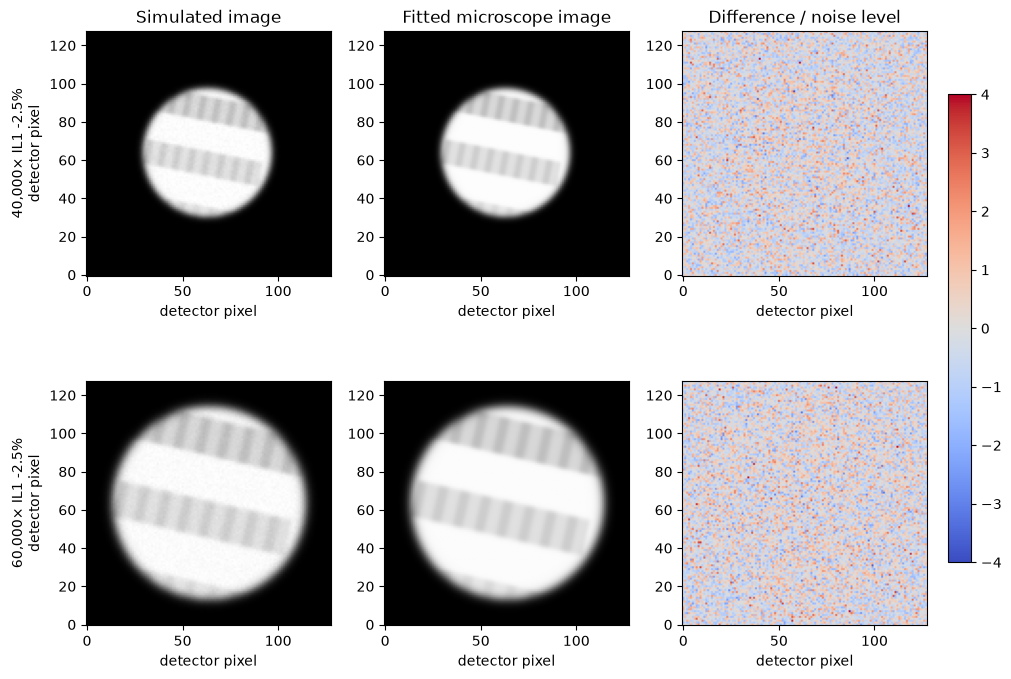

In [10]:
show_image_fit(
    experiment=experiment,
    measurements=measurements,
    fit_result=fit_with_tilts,
    indices=[1, 10],                  # one wobble at each magnification
)

## 7. Explore the original fit

Each of our 19 parameters is one direction in the fitting space. The height is the squared measurement error, weighted by its uncertainty, plus the prior penalty. A low region may be a separate minimum or a long valley of similar microscopes.

**Supply:** the original measurements, one fixed prior model, 20 different starting models, and detector positions to scan.

**Get back:** all fitted models and a detector-position profile. At each detector position, the other 18 parameters are refitted. Two sweeps approach the grid from opposite directions; we retain the lower converged error. Promising unfinished runs receive additional iterations. The starting models are identical in both experiments, and the prior centres stay fixed.

These are searches for competing solutions, not an exhaustive count of minima. A converged fit can still be a poor local solution.

In [11]:
starting_models = make_starting_models(
    prior_model=starting_guess,
    position_priors=position_priors,
    number_of_starts=20,
    random_seed=482,
)
detector_positions_mm = np.linspace(640, 840, 11)

original_landscape = explore_fit_landscape(
    lens_controls=experiment.lens_controls,
    image_measurements=measurements,
    tilt_measurements=tilt_measurements,
    specimen_and_detector=experiment.specimen_and_detector,
    prior_model=starting_guess,
    position_priors=position_priors,
    starting_models=starting_models,
    detector_positions_mm=detector_positions_mm,
    output_directory=experiment.output_directory / "original_landscape",
)

Start 1/20: total error 46.984, converged


Start 2/20: total error 14521043.562, converged


Start 3/20: total error 46.984, converged


Start 4/20: total error 14521011.075, converged


Start 5/20: total error 49.993, not converged


Start 6/20: total error 55.379, not converged


... (41 outputs left out)

Detector 700 mm (reverse): total error 49.077, converged


Detector 680 mm (reverse): total error 51.111, converged


Detector 660 mm (reverse): total error 53.871, converged


Detector 640 mm (reverse): total error 57.388, converged


## 8. Add stronger wobbles at 40,000×

Take ±5% and ±10% wobbles of each of IL1–PL1, giving **16 additional images**. At the negative IL1 setting for each wobble size, also take the same calibrated tilt pairs, giving **eight additional tilt images**. The circular illumination still fits at these 40,000× settings.

The original exposures stay unchanged. The expanded fit uses **34 ordinary images and 16 tilt images**. New measurements still come from noisy pixels, with the same specimen, exposure rule and drift model.

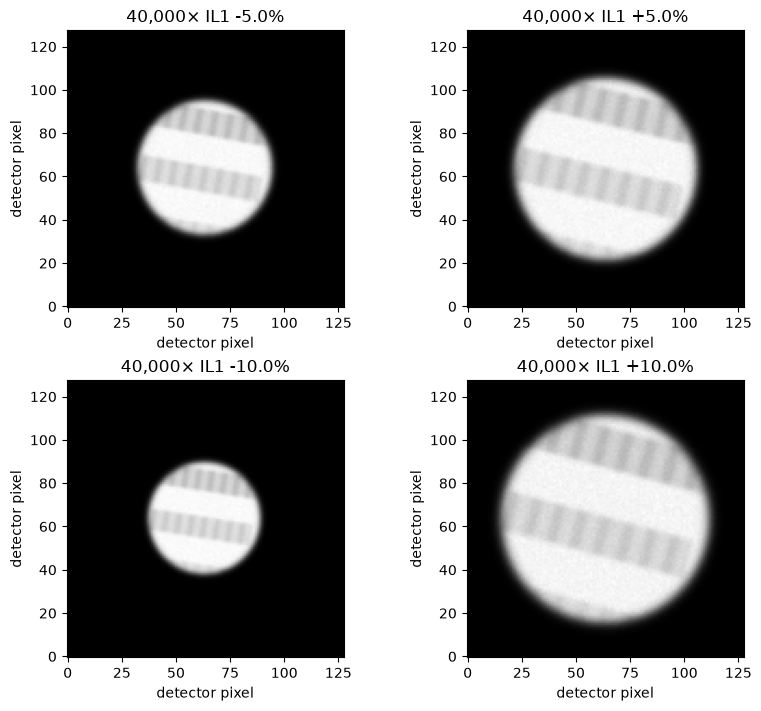

In [12]:
extra_experiment = simulate_extra_wobbles(
    experiment=experiment,
    reference_image_index=0,           # 40,000× reference controls
    wobble_fractions=[0.05, 0.10],
    random_seed=825,
)
extra_measurements = measure_extra_wobble_images(
    experiment=extra_experiment,
    reference_measurements=measurements,
    reference_image_index=0,           # use the measured 40,000× reference to start
)

show_images(
    images=extra_experiment.images,
    image_labels=extra_experiment.image_labels,
    indices=[0, 1, 8, 9],              # IL1 ±5%, then IL1 ±10%
)

In [13]:
extra_tilt_experiment = simulate_tilt_images(
    experiment=extra_experiment,
    lens_setting_indices=[0, 8],       # IL1 −5% and −10% at 40,000×
    tilt_mrad=1.0,
    drift_std_pixels=0.003,
    random_seed=914,
)
extra_tilt_measurements = measure_tilt_images(
    tilt_experiment=extra_tilt_experiment,
    specimen_template=extra_experiment.specimen_template,
    specimen_and_detector=extra_experiment.specimen_and_detector,
    reference_measurements=extra_measurements,
)
show_tilt_measurements(extra_tilt_measurements)

Lens setting / tilt direction,Measured dx (pixels),Measured dy (pixels)
"40,000× IL1 -5.0%, x tilt",-0.3634 ± 0.0045,+0.1074 ± 0.0045
"40,000× IL1 -5.0%, y tilt",-0.1119 ± 0.0045,-0.3471 ± 0.0045
"40,000× IL1 -10.0%, x tilt",-0.6921 ± 0.0045,+0.1971 ± 0.0045
"40,000× IL1 -10.0%, y tilt",-0.1965 ± 0.0045,-0.6964 ± 0.0045


## 9. Repeat the same searches with the extra measurements

Combine the independent measurements, then reuse exactly the same starting models, priors and detector-position grid.

In [14]:
expanded_measurements = combine_image_measurements(measurements, extra_measurements)
expanded_tilts = combine_tilt_measurements(tilt_measurements, extra_tilt_measurements)
expanded_controls = np.concatenate([experiment.lens_controls, extra_experiment.lens_controls])

expanded_landscape = explore_fit_landscape(
    lens_controls=expanded_controls,
    image_measurements=expanded_measurements,
    tilt_measurements=expanded_tilts,
    specimen_and_detector=experiment.specimen_and_detector,
    prior_model=starting_guess,
    position_priors=position_priors,
    starting_models=starting_models,
    detector_positions_mm=detector_positions_mm,
    output_directory=experiment.output_directory / "expanded_landscape",
)

Start 1/20: total error 105.831, converged


Start 2/20: total error 12324817237.292, converged


Start 3/20: total error 105.831, converged


Start 4/20: total error 21818411.586, converged


Start 5/20: total error 112.827, not converged


Start 6/20: total error 116.825, not converged


... (41 outputs left out)

Detector 700 mm (reverse): total error 106.155, converged


Detector 680 mm (reverse): total error 107.859, converged


Detector 660 mm (reverse): total error 111.050, converged


Detector 640 mm (reverse): total error 115.763, converged


## 10. Compare the landscapes

The scatter plots show where the fits ended and their error above the best solution for that data set. Grey crosses mark fits that stopped without convergence. Separated low-error groups suggest competing solutions; a spread of similarly good positions suggests a shallow valley.

The profile plots show the best error found at each fixed detector position. The left panel includes the fixed priors. The right shows the data contribution **at those same fitted models**, not a separately optimised data-only profile. Narrower profiles mean detector position is more strongly constrained under these assumptions.

Dotted vertical lines mark the generating positions, opened only now for scoring. The count within one error unit is a descriptive count of fitted endpoints, not a count of distinct minima or a confidence interval.

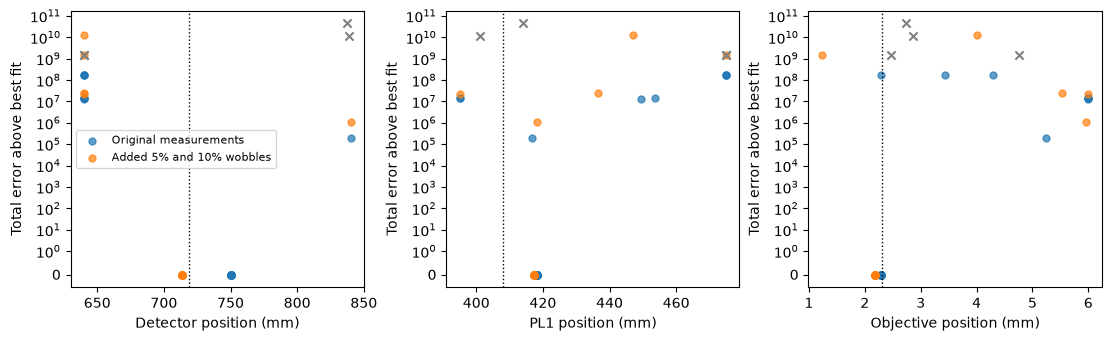

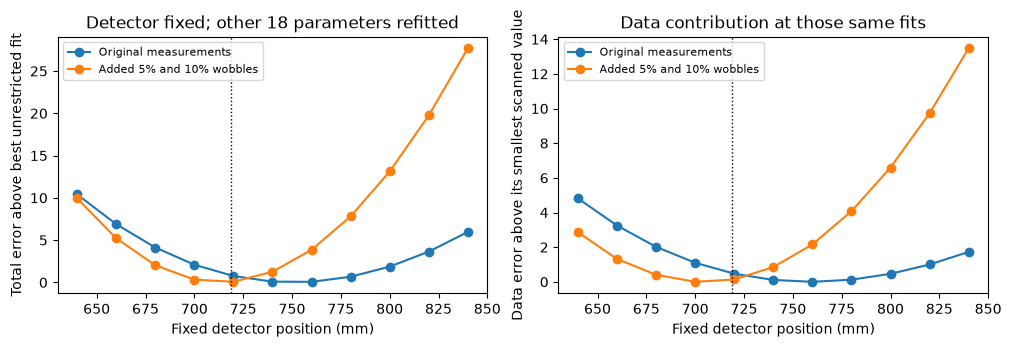

Measurements,Converged fits,Within 1 error unit of best,Their detector positions (mm),Best detector position (mm)
Original measurements,19/20,11,750.64–750.65,750.64
Added 5% and 10% wobbles,17/20,12,713.39–713.40,713.40


An error unit is one squared residual divided by its measurement variance. The near-best count counts fitted endpoints, not distinct minima. Profiles use the same fixed priors; the right panel is their data contribution, not a separately optimized data-only profile.


In [15]:
true_model = load_simulated_truth(output_directory=experiment.output_directory)

compare_fit_landscapes(
    original=original_landscape,
    extra_wobbles=expanded_landscape,
    true_model=true_model,
)

For these simulated images, **11 of 20** original-data starts and **12 of 20** expanded-data starts reached the same low-error cluster for their respective data set. The other outcomes were much poorer fits or did not converge. These searches found no second similarly good cluster.

The stronger wobbles and their tilt measurements narrow the detector profile. The best detector position moves from **750.64 mm to 713.40 mm**, compared with **718.75 mm** in the generating model: an error reduction from **31.9 mm to 5.35 mm**. Some lens positions remain inaccurate.

The tight clustering of fitted endpoints shows optimizer repeatability, not a narrow uncertainty interval. The detector profile remains broad, includes the fixed priors, and samples a finite grid.

Helpers: [image analysis and fitting](projector_notebook_helpers.py), [calibrated tilts](projector_tilt_pipeline.py), [extra wobbles and landscape searches](projector_landscape.py).

## 11. Add ±3 mrad tilts

Keep all existing measurements and add **−3 and +3 mrad** tilts along both axes at the same four lens settings. That adds **16 images**, giving **34 ordinary images and 32 tilt images** in total.

The angle difference within each new pair is **6 mrad**, versus 2 mrad for the old pairs, so the predicted displacement is three times larger. This strengthens the same $B$ measurement; it does not introduce a new matrix block. Exposure per image, frame drift, lens controls, priors and starting models stay unchanged. The tilt calibration remains exact in this simulation.

In [16]:
three_mrad_experiment = simulate_tilt_images(
    experiment=experiment,
    lens_setting_indices=[1, 10],      # IL1 −2.5% at 40,000× and 60,000×
    tilt_mrad=3.0,
    drift_std_pixels=0.003,
    random_seed=915,
)
three_mrad_measurements = measure_tilt_images(
    tilt_experiment=three_mrad_experiment,
    specimen_template=experiment.specimen_template,
    specimen_and_detector=experiment.specimen_and_detector,
    reference_measurements=measurements,
)

three_mrad_extra_experiment = simulate_tilt_images(
    experiment=extra_experiment,
    lens_setting_indices=[0, 8],       # IL1 −5% and −10% at 40,000×
    tilt_mrad=3.0,
    drift_std_pixels=0.003,
    random_seed=916,
)
three_mrad_extra_measurements = measure_tilt_images(
    tilt_experiment=three_mrad_extra_experiment,
    specimen_template=extra_experiment.specimen_template,
    specimen_and_detector=extra_experiment.specimen_and_detector,
    reference_measurements=extra_measurements,
)

show_tilt_measurements(three_mrad_extra_measurements)

Lens setting / tilt direction,Measured dx (pixels),Measured dy (pixels)
"40,000× IL1 -5.0%, x tilt ±3 mrad",-1.0535 ± 0.0045,+0.3341 ± 0.0045
"40,000× IL1 -5.0%, y tilt ±3 mrad",-0.3299 ± 0.0045,-1.0510 ± 0.0045
"40,000× IL1 -10.0%, x tilt ±3 mrad",-2.0720 ± 0.0045,+0.5936 ± 0.0045
"40,000× IL1 -10.0%, y tilt ±3 mrad",-0.5927 ± 0.0045,-2.0834 ± 0.0045


Refit with the same 20 starting models and detector-position scan. The **only additions** are the measured ±3 mrad image-pair shifts. Every original observation is included once.

In [17]:
one_and_three_mrad_measurements = combine_tilt_measurements(
    expanded_tilts,
    three_mrad_measurements,
    three_mrad_extra_measurements,
)

three_mrad_landscape = explore_fit_landscape(
    lens_controls=expanded_controls,
    image_measurements=expanded_measurements,
    tilt_measurements=one_and_three_mrad_measurements,
    specimen_and_detector=experiment.specimen_and_detector,
    prior_model=starting_guess,
    position_priors=position_priors,
    starting_models=starting_models,
    detector_positions_mm=detector_positions_mm,
    output_directory=experiment.output_directory / "three_mrad_landscape",
)

Start 1/20: total error 116.856, not converged


Start 2/20: total error 12594708569.043, converged


Start 3/20: total error 116.819, converged


Start 4/20: total error 206460216.241, converged


Start 5/20: total error 121.634, not converged


Start 6/20: total error 145.962, converged


... (40 outputs left out)

Detector 700 mm (reverse): total error 117.086, converged


Detector 680 mm (reverse): total error 118.706, converged


Detector 660 mm (reverse): total error 121.821, converged


Detector 640 mm (reverse): total error 126.466, converged


## 12. Did the larger tilts help?

Compare the detector profiles and errors against the generating model. Both $B$ errors are evaluated at the **same four lens settings**. A smaller error in one noise realization is a recovery result; the profile shows how tightly detector position is constrained under our fixed priors.

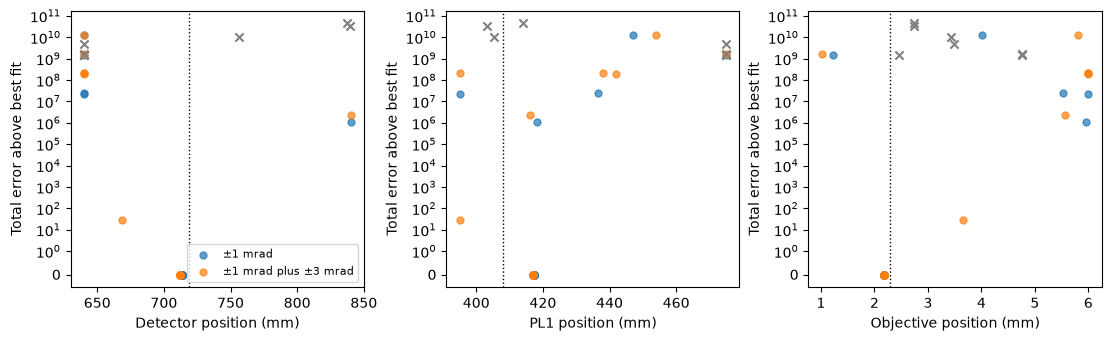

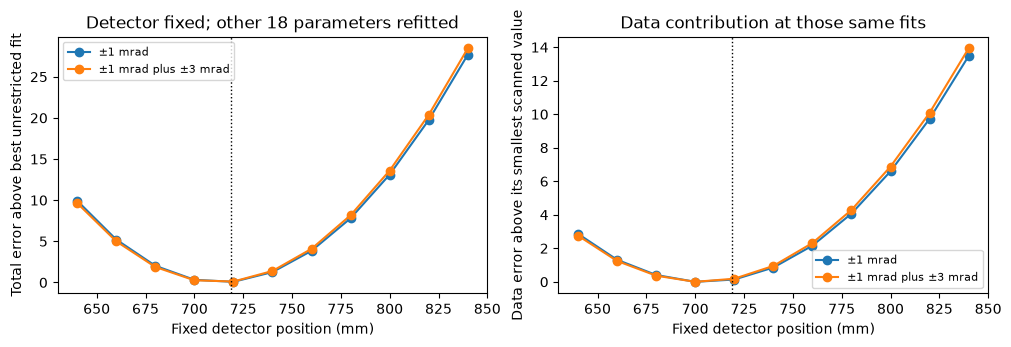

Measurements,Converged fits,Within 1 error unit of best,Their detector positions (mm),Best detector position (mm)
±1 mrad,17/20,12,713.39–713.40,713.40
±1 mrad plus ±3 mrad,16/20,9,712.09–712.12,712.10


An error unit is one squared residual divided by its measurement variance. The near-best count counts fitted endpoints, not distinct minima. Profiles use the same fixed priors; the right panel is their data contribution, not a separately optimized data-only profile.


Element,True z (mm),±1 mrad fit,±1 and ±3 mrad fit,Old position error (mm),New position error (mm)
Objective,2.300,2.179,2.176,-0.121,-0.124
IL1,213.524,210.390,211.072,-3.134,-2.452
IL2,290.480,293.868,294.135,+3.388,+3.655
IL3,352.980,360.303,360.207,+7.323,+7.227
PL1,407.983,417.377,417.006,+9.394,+9.022
Detector,718.750,713.401,712.100,-5.349,-6.650


±1 mrad: relative B error at the same measured lens settings = 0.457%
±1 mrad plus ±3 mrad: relative B error at the same measured lens settings = 0.146%


In [18]:
true_model = load_simulated_truth(output_directory=experiment.output_directory)

tilt_amplitude_comparison = compare_tilt_amplitudes(
    one_mrad=expanded_landscape,
    one_and_three_mrad=three_mrad_landscape,
    lens_controls=expanded_tilts["lens_controls"],
    true_model=true_model,             # scoring only
)

For the supplied random seeds, adding ±3 mrad tilts reduces the error in $B$ from **0.457% to 0.146%** at the same four lens settings. The original image files are unchanged.

The detector-position profile is almost unchanged, while the detector-position error moves from **5.35 mm to 6.65 mm** in this noise realization. The larger tilts improve the angular-response estimate, but the remaining geometry uncertainty appears to be dominated by other parameter correlations. Point errors from one realization are not uncertainty intervals.

## 13. Add calibrated beam shifts

Move the beam by **−10 and +10 nm** along each axis at the same four lens settings. Keep its mean angle fixed. This adds **16 MAGICAL images**, giving **82 images** in total. Position and angle calibration are exact here; exposure and frame drift follow the earlier experiment.

**Keep the specimen fixed and visible.** Move the circular illumination across the same MAGICAL region. This changes which part of the specimen is lit; it does not simply translate the whole image.

Write a ray's position relative to the moving beam centre as $\mathbf u$:

$$
\mathbf r_s=\mathbf s+\mathbf u,\qquad
\boldsymbol\theta_s=h\mathbf u+\boldsymbol\alpha+\boldsymbol\epsilon.
$$

The beam and its wavefront move together, keeping the same unknown curvature $h$ and angular spread. Moving only the intensity envelope over a fixed curved wavefront would be a different experiment. A pair gives the illumination-centre motion

$$
\Delta\mathbf r_d=A\,\Delta\mathbf s+B\,\Delta\boldsymbol\alpha.
$$

Here $\Delta\boldsymbol\alpha=0$: the 20 nm separation measures $A$. The earlier tilts measure $B$, while specimen features measure $A+hB$. This is the extra information we are testing. Known angle changes accompanying a real beam shift can also be supplied to the helper.

**Supply:** existing lens settings, beam-shift amplitude and noise settings.

**Get back:** noisy images of the same specimen under shifted illumination, and the calibrated input positions. The illumination keeps its 100 nm radius and the same soft edge.

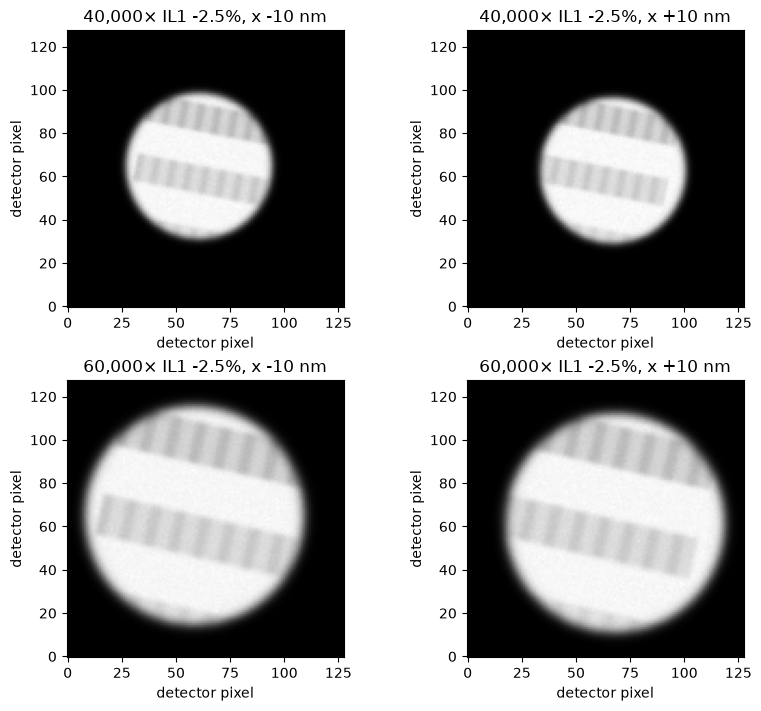

In [19]:
beam_shift_experiment = simulate_beam_shift_images(
    experiment=experiment,
    lens_setting_indices=[1, 10],      # IL1 −2.5% at 40,000× and 60,000×
    shift_nm=10.0,                    # each axis: −10 nm, then +10 nm
    drift_std_pixels=0.003,
    random_seed=917,
)
extra_beam_shift_experiment = simulate_beam_shift_images(
    experiment=extra_experiment,
    lens_setting_indices=[0, 8],       # IL1 −5% and −10% at 40,000×
    shift_nm=10.0,
    drift_std_pixels=0.003,
    random_seed=918,
)

show_images(
    images=beam_shift_experiment.images,
    image_labels=beam_shift_experiment.image_labels,
    indices=[0, 1, 4, 5],             # x-shift pairs at both magnifications
)

**Supply:** beam-shift images, the known specimen template and detector settings. Earlier image measurements give the registration a starting point.

**Get back:** measured illumination-centre differences in pixels, their uncertainties, and the calibrated position changes in metres.

Image analysis fits the specimen pattern's scale, rotation, blur and translation, plus brightness, background and the illumination's centre relative to the specimen. It uses both the visible specimen texture and the circular boundary to separate their motions. It receives no true lens parameters or calibrated beam positions while fitting the pixels.

The measured beam centre is the centre of the fitted illumination boundary, not the brightness-weighted centre of the textured image. Only centre differences enter the microscope fit. Their covariance includes uncertainty in all nine image parameters and independent frame drift. Each pair uses separate exposures; its shared image offset cancels.

In [20]:
beam_shift_measurements = measure_beam_shift_images(
    beam_shift_experiment=beam_shift_experiment,
    specimen_template=experiment.specimen_template,
    specimen_and_detector=experiment.specimen_and_detector,
    reference_measurements=measurements,
)
extra_beam_shift_measurements = measure_beam_shift_images(
    beam_shift_experiment=extra_beam_shift_experiment,
    specimen_template=extra_experiment.specimen_template,
    specimen_and_detector=extra_experiment.specimen_and_detector,
    reference_measurements=extra_measurements,
)
all_beam_shift_measurements = combine_beam_shift_measurements(
    beam_shift_measurements,
    extra_beam_shift_measurements,
)

show_beam_shift_measurements(all_beam_shift_measurements)

MAGICAL beam-shift image 1/8: weighted pixel RMS 0.972


MAGICAL beam-shift image 2/8: weighted pixel RMS 0.980


MAGICAL beam-shift image 3/8: weighted pixel RMS 0.965


MAGICAL beam-shift image 4/8: weighted pixel RMS 0.972


MAGICAL beam-shift image 5/8: weighted pixel RMS 0.999


MAGICAL beam-shift image 6/8: weighted pixel RMS 0.998


... (7 outputs left out)

MAGICAL beam-shift image 6/8: weighted pixel RMS 0.976


MAGICAL beam-shift image 7/8: weighted pixel RMS 0.971


MAGICAL beam-shift image 8/8: weighted pixel RMS 0.968


Pair,"Known dx, dy (nm)",Measured dx (pixels),Measured dy (pixels)
"40,000× IL1 -2.5%, x shift ±10 nm","+20, +0",+6.3937 ± 0.0046,-2.0942 ± 0.0046
"40,000× IL1 -2.5%, y shift ±10 nm","+0, +20",+2.0926 ± 0.0046,+6.4003 ± 0.0046
"60,000× IL1 -2.5%, x shift ±10 nm","+20, +0",+9.4843 ± 0.0046,-3.4325 ± 0.0046
"60,000× IL1 -2.5%, y shift ±10 nm","+0, +20",+3.4373 ± 0.0046,+9.4865 ± 0.0046
"40,000× IL1 -5.0%, x shift ±10 nm","+20, +0",+5.9131 ± 0.0045,-1.8489 ± 0.0045
"40,000× IL1 -5.0%, y shift ±10 nm","+0, +20",+1.8534 ± 0.0045,+5.9142 ± 0.0045
"40,000× IL1 -10.0%, x shift ±10 nm","+20, +0",+4.9735 ± 0.0045,-1.4135 ± 0.0045
"40,000× IL1 -10.0%, y shift ±10 nm","+0, +20",+1.4074 ± 0.0045,+4.9688 ± 0.0045


## 14. Fit with the new measurement axis

**Supply:** all earlier image and tilt measurements, plus the measured beam shifts. Use the same 20 starting models, fixed priors and detector-position grid.

**Get back:** fitted microscope models and the detector-position profile. The only new residual is the difference between the measured beam-centre motion and the model's predicted motion, weighted by its uncertainty. All 19 microscope parameters remain free in each unrestricted fit.

In [21]:
beam_shift_landscape = explore_fit_landscape(
    lens_controls=expanded_controls,
    image_measurements=expanded_measurements,
    tilt_measurements=one_and_three_mrad_measurements,
    beam_shift_measurements=all_beam_shift_measurements,
    specimen_and_detector=experiment.specimen_and_detector,
    prior_model=starting_guess,
    position_priors=position_priors,
    starting_models=starting_models,
    detector_positions_mm=detector_positions_mm,
    output_directory=experiment.output_directory / "beam_shift_landscape",
)

Start 1/20: total error 122.281, converged


Start 2/20: total error 12608411574.685, converged


Start 3/20: total error 122.281, converged


Start 4/20: total error 226900949.852, converged


Start 5/20: total error 122.281, converged


Start 6/20: total error 122.281, converged


... (33 outputs left out)

Detector 700 mm (reverse): total error 122.450, converged


Detector 680 mm (reverse): total error 124.211, converged


Detector 660 mm (reverse): total error 127.928, converged


Detector 640 mm (reverse): total error 133.658, converged


## 15. Did beam shifts help?

Compare $A$ and $B$ errors at the same four lens settings, the fitted curvature and positions, and the detector-position profile. Smaller errors show better recovery for these simulated images. A narrower profile shows a stronger constraint under the same priors. Neither the 20 starts nor a single noise realization proves that every lens parameter is uniquely determined.

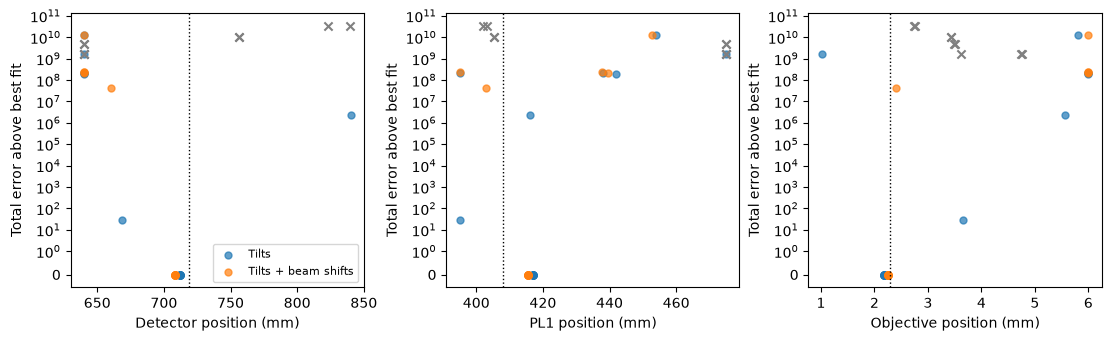

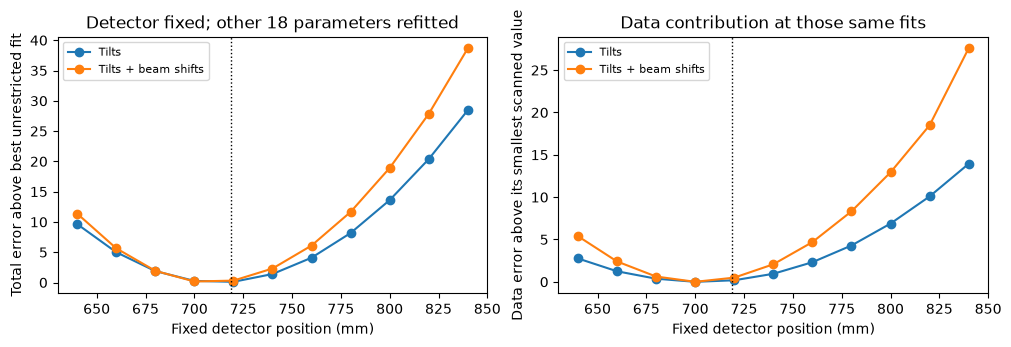

Measurements,Converged fits,Within 1 error unit of best,Their detector positions (mm),Best detector position (mm)
Tilts,16/20,9,712.09–712.12,712.10
Tilts + beam shifts,15/20,10,708.46–708.46,708.46


An error unit is one squared residual divided by its measurement variance. The near-best count counts fitted endpoints, not distinct minima. Profiles use the same fixed priors; the right panel is their data contribution, not a separately optimized data-only profile.


Quantity,Truth,Tilts,Tilts + beam shifts
A error,0%,0.1810%,0.0324%
B error,0%,0.1457%,0.1252%
Curvature (1/m),2000.000,-799.144,1516.643
Detector z (mm),718.750,712.100,708.463


Lens,True z (mm),Tilts,Tilts + beam shifts,Old error (mm),New error (mm)
Objective,2.300,2.176,2.256,-0.124,-0.044
IL1,213.524,211.072,213.955,-2.452,+0.432
IL2,290.480,294.135,294.945,+3.655,+4.465
IL3,352.980,360.207,359.685,+7.227,+6.705
PL1,407.983,417.006,415.548,+9.022,+7.564


In [22]:
beam_shift_comparison = compare_beam_shift_fits(
    without_beam_shifts=three_mrad_landscape,
    with_beam_shifts=beam_shift_landscape,
    lens_controls=all_beam_shift_measurements["lens_controls"],
    true_model=load_simulated_truth(output_directory=experiment.output_directory),
)

For these simulated images, adding beam shifts reduces the **$A$ error from 0.181% to 0.032%**. The $B$ error changes from **0.146% to 0.125%**. Fitted beam curvature moves from **−799 to 1517 m⁻¹**, toward the true **2000 m⁻¹**.

The geometry result is mixed. The detector profile is somewhat narrower, but its fitted position changes from **712.10 to 708.46 mm**, compared with the true **718.75 mm**. Its point error therefore increases from **6.65 to 10.29 mm** in this noise realization. The objective and IL1 positions improve; other lens positions still have errors.

Beam shifts add useful information about $A$ and illumination curvature. They do not yet determine every internal lens parameter tightly. This result assumes calibrated position and mean angle, a stable moving wavefront, and our known specimen intensity template. The MAGICAL feature remains visible throughout the experiment.

Continue in the [adaptive calibration notebook](projector_adaptive_calibration.ipynb): it tests mixed-lens settings, objective variation and a two-stage fit. The later synthetic experiment recovers all 19 parameters within 0.11%, checks fresh predictions and repeats the noise.